In [8]:
%cd /content/llm-qa-project
!git fetch origin
!git checkout analysis
!git pull
!python -m src.compare_results

/content/llm-qa-project
remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 7 (delta 4), reused 7 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 7.20 KiB | 2.40 MiB/s, done.
From https://github.com/Kairos-025/llm-qa-project
   2f00d20..8f44696  analysis   -> origin/analysis
M	results/comparison.csv
Already on 'analysis'
Your branch is behind 'origin/analysis' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
Updating 2f00d20..8f44696
Fast-forward
 notebooks/00_setup.ipynb    |  32 ++--
 notebooks/05_analysis.ipynb |  96 +++++++++++
 src/analysis.py             | 378 ++++++++++++++++++++++++++++++++++++++++++++
 3 files changed, 490 insertions(+), 16 deletions(-)
 create mode 100644 notebooks/05_analysis.ipynb
 create mode 100644 src/analysis.py
Method              EM    F1     Lenient acc  Ans F1  Unans acc  BLEU   ROUGE-L  Minutes
-------

In [9]:
!python -m src.analysis \
    --compare finetuned fewshot5 \
    --compare finetuned rag_k1 \
    --compare finetuned finetuned_natural \
    --compare finetuned finetuned_size2000 \
    --compare finetuned_rag_k1 rag_k1 \
    --compare finetuned_rag_k1 finetuned_rag_k3 \
    --compare fewshot5 structured

method                     F1  95% CI
finetuned_natural       85.70  [83.43, 87.76]
finetuned               85.41  [83.28, 87.51]
finetuned_size2000      82.77  [80.57, 85.03]
finetuned_size1000      80.79  [78.33, 83.11]
finetuned_size500       79.87  [77.43, 82.20]
finetuned_rag_k1        74.28  [71.66, 76.90]
finetuned_rag_k3        72.28  [69.52, 74.99]
fewshot5                62.71  [59.83, 65.58]
structured              62.47  [59.66, 65.25]
instructed              61.99  [59.07, 64.74]
rag_k1                  58.43  [55.52, 61.41]
fewshot3                56.38  [53.58, 59.36]
rag_k3                  55.95  [53.08, 58.94]
cot                     54.07  [51.17, 57.18]
rag_k5                  51.69  [48.73, 54.64]
fewshot1                47.07  [44.32, 49.83]
baseline                17.51  [16.16, 18.92]

finetuned vs fewshot5 (difference A - B, 95% interval, p):
  F1                 +22.70  [+19.80, +25.89]  p < 0.001  real difference
  Answerable F1      +10.15  [+6.58, +13.97]  

In [10]:
import pandas as pd
for f in ["confidence_intervals", "paired_tests", "error_types"]:
    print(f"\n=== {f} ===")
    display(pd.read_csv(f"results/analysis/{f}.csv"))


=== confidence_intervals ===


,method,n,f1,f1_low,f1_high,em,em_low,em_high,ans_f1,ans_f1_low,ans_f1_high,unans_acc,unans_low,unans_high
0,finetuned_natural,1000,85.70,83.43,87.76,83.3,80.9,85.5,85.00,81.96,88.03,86.39,83.20,89.46
1,finetuned,1000,85.41,83.28,87.51,82.8,80.3,85.2,80.76,77.56,84.11,89.94,87.25,92.40
2,finetuned_size2000,1000,82.77,80.57,85.03,79.5,77.0,82.1,77.22,73.63,80.57,88.17,85.23,91.04
3,finetuned_size1000,1000,80.79,78.33,83.11,78.0,75.3,80.5,72.80,68.81,76.42,88.56,85.74,91.21
4,finetuned_size500,1000,79.87,77.43,82.20,77.2,74.6,79.8,70.33,66.48,74.14,89.15,86.42,91.72
5,finetuned_rag_k1,1000,74.28,71.66,76.90,72.1,69.4,74.9,58.79,54.58,62.86,89.35,86.67,91.95
6,finetuned_rag_k3,1000,72.28,69.52,74.99,69.4,66.5,72.3,68.91,64.86,72.95,75.54,71.92,79.09
7,fewshot5,1000,62.71,59.83,65.58,56.5,53.5,59.7,70.61,67.07,74.33,55.03,50.62,59.30
8,structured,1000,62.47,59.66,65.25,55.2,52.1,58.3,77.23,74.04,80.41,48.13,43.89,52.41
9,instructed,1000,61.99,59.07,64.74,54.7,51.6,57.7,79.90,76.79,82.75,44.58,40.33,48.91



=== paired_tests ===


,a,b,n,f1_diff,f1_ci_low,f1_ci_high,f1_p,ans_f1_diff,ans_f1_ci_low,ans_f1_ci_high,ans_f1_p,unans_acc_diff,unans_acc_ci_low,unans_acc_ci_high,unans_acc_p
0,finetuned,fewshot5,1000,22.70,19.80,25.89,0.000,10.15,6.58,13.97,0.000,34.91,30.02,39.53,0.000
1,finetuned,rag_k1,1000,26.99,23.89,30.16,0.000,23.30,19.27,27.35,0.000,30.57,26.08,35.04,0.000
2,finetuned,finetuned_natural,1000,-0.29,-1.87,1.24,0.726,-4.24,-6.54,-2.23,0.000,3.55,1.41,5.87,0.003
3,finetuned,finetuned_size2000,1000,2.64,1.21,4.08,0.000,3.54,1.42,5.83,0.001,1.78,-0.19,3.73,0.095
4,finetuned_rag_k1,rag_k1,1000,15.86,13.35,18.58,0.000,1.33,-1.25,4.09,0.289,29.98,25.96,33.94,0.000
5,finetuned_rag_k1,finetuned_rag_k3,1000,2.01,-0.37,4.58,0.101,-10.12,-13.67,-6.70,0.000,13.81,10.67,17.15,0.000
6,fewshot5,structured,1000,0.24,-2.54,2.82,0.851,-6.62,-9.89,-3.36,0.000,6.90,2.75,11.04,0.001



=== error_types ===


,method,n_answerable,n_unanswerable,exact,partial,wrong answer,wrongly abstained,correct abstain,made-up answer
0,baseline,493,507,1,479,13,0,18,489
1,cot,493,507,336,107,45,5,138,369
2,fewshot1,493,507,243,216,27,7,121,386
3,fewshot3,493,507,313,138,27,15,175,332
4,fewshot5,493,507,286,108,21,78,279,228
5,finetuned_natural,493,507,395,37,14,47,438,69
6,finetuned,493,507,372,42,8,71,456,51
7,finetuned_rag_k1,493,507,268,35,23,167,453,54
8,finetuned_rag_k3,493,507,311,50,25,107,383,124
9,finetuned_size1000,493,507,331,46,8,108,449,58


In [11]:
qt = pd.read_csv("results/analysis/by_question_type.csv")
keep = ["baseline", "fewshot5", "rag_k1", "finetuned", "finetuned_rag_k1"]
display(qt[qt.method.isin(keep)].pivot(index="qtype", columns="method", values="ans_f1"))
display(qt[qt.method.isin(keep)].pivot(index="qtype", columns="method", values="unans_acc"))

method,baseline,fewshot5,finetuned,finetuned_rag_k1,rag_k1
qtype,,,,,
how,29.20,42.64,86.54,51.15,43.99
how many,27.78,70.93,98.67,85.33,83.33
how much,41.28,45.00,71.43,57.14,50.71
other,31.17,37.86,60.00,45.33,50.00
what,31.88,72.10,79.83,57.56,56.26
when,31.81,84.51,93.41,83.33,75.40
where,31.56,63.27,84.02,61.94,44.23
which,32.57,78.33,72.99,43.82,53.91
who,33.00,64.27,75.76,44.24,50.90


method,baseline,fewshot5,finetuned,finetuned_rag_k1,rag_k1
qtype,,,,,
how,0.00,71.43,92.86,92.86,85.71
how many,13.79,68.97,82.76,75.86,82.76
how much,44.44,77.78,77.78,88.89,88.89
other,0.00,100.00,100.00,100.00,100.00
what,2.39,53.43,90.45,89.55,54.03
when,0.00,68.97,82.76,82.76,72.41
where,4.76,28.57,95.24,90.48,42.86
which,0.00,47.83,95.65,91.30,56.52
who,0.00,45.45,93.94,96.97,60.61


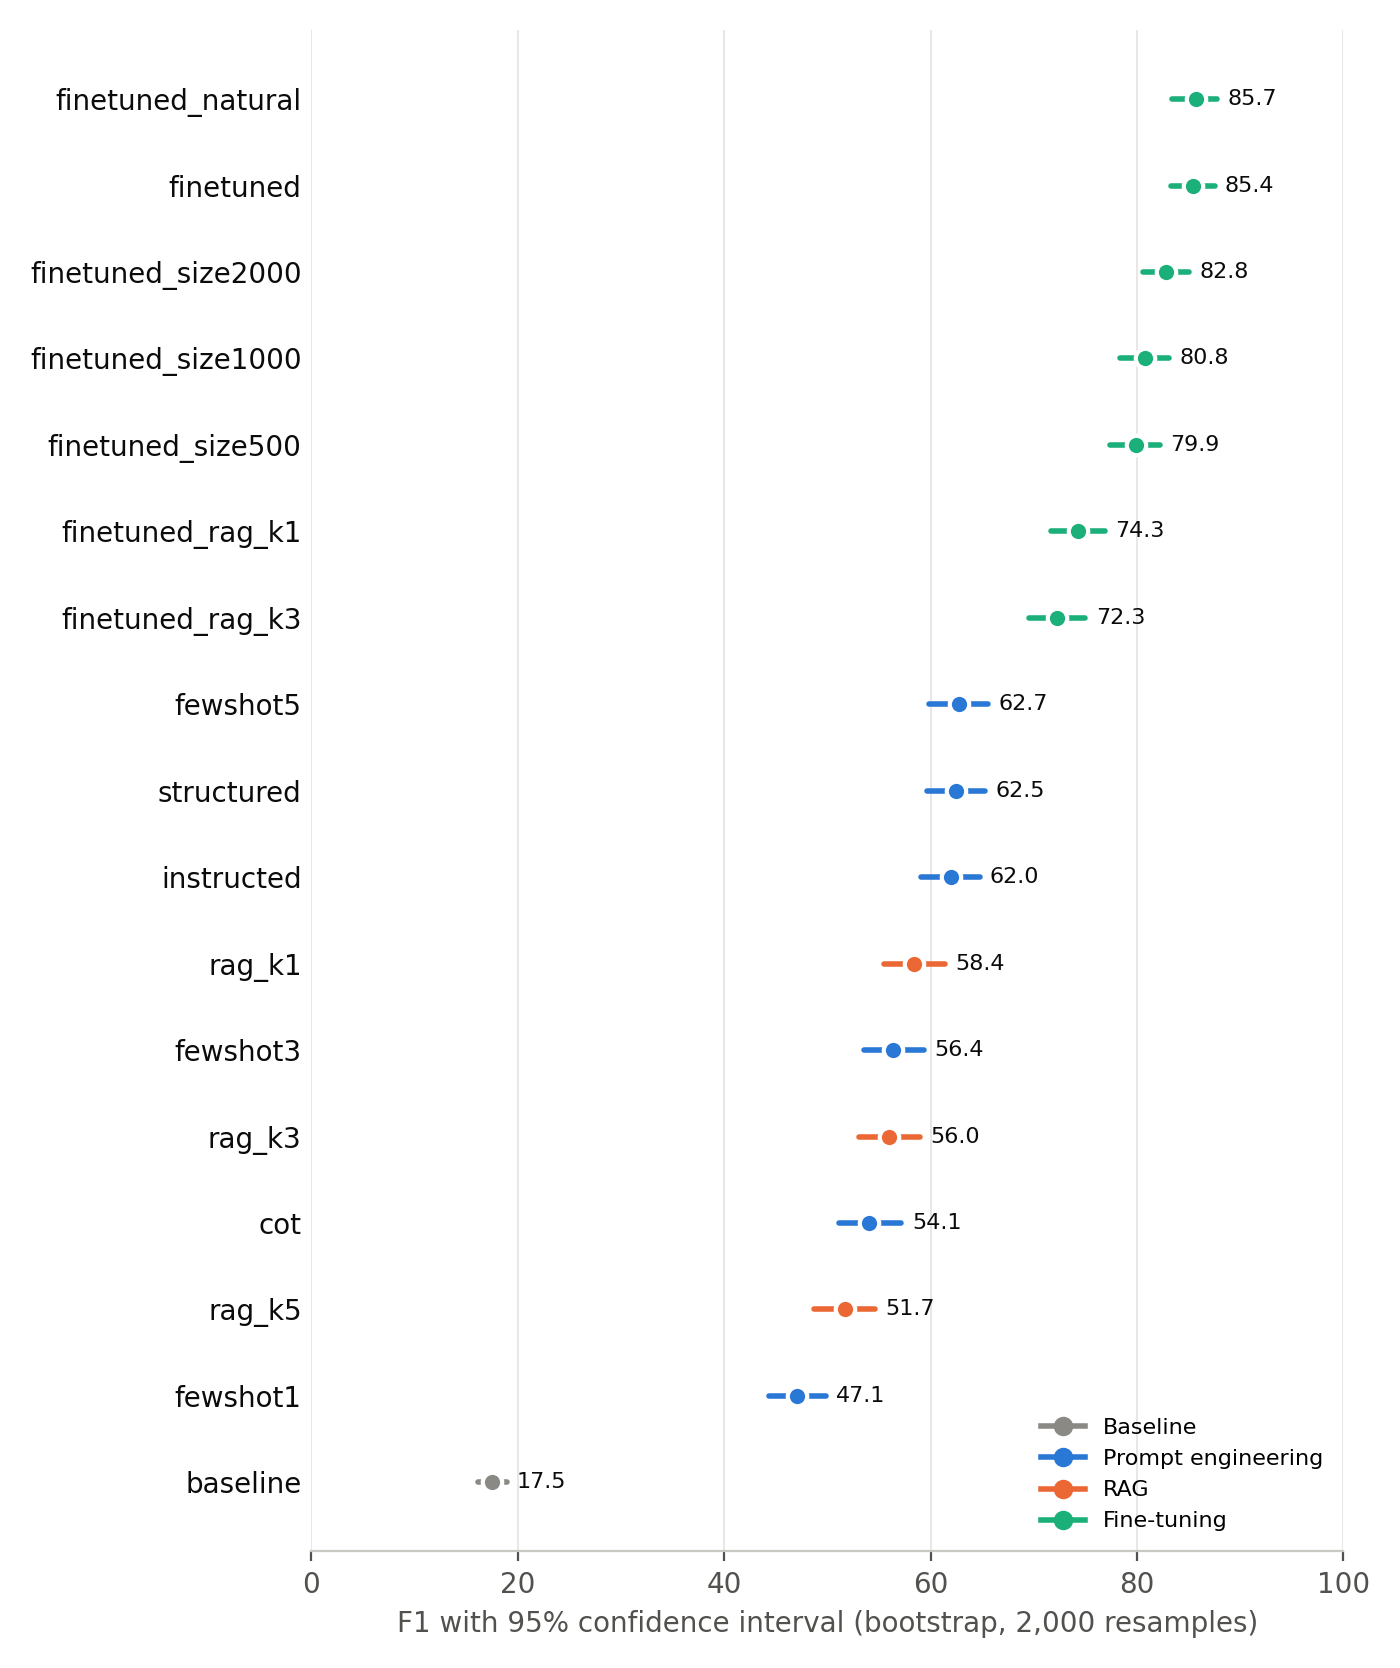

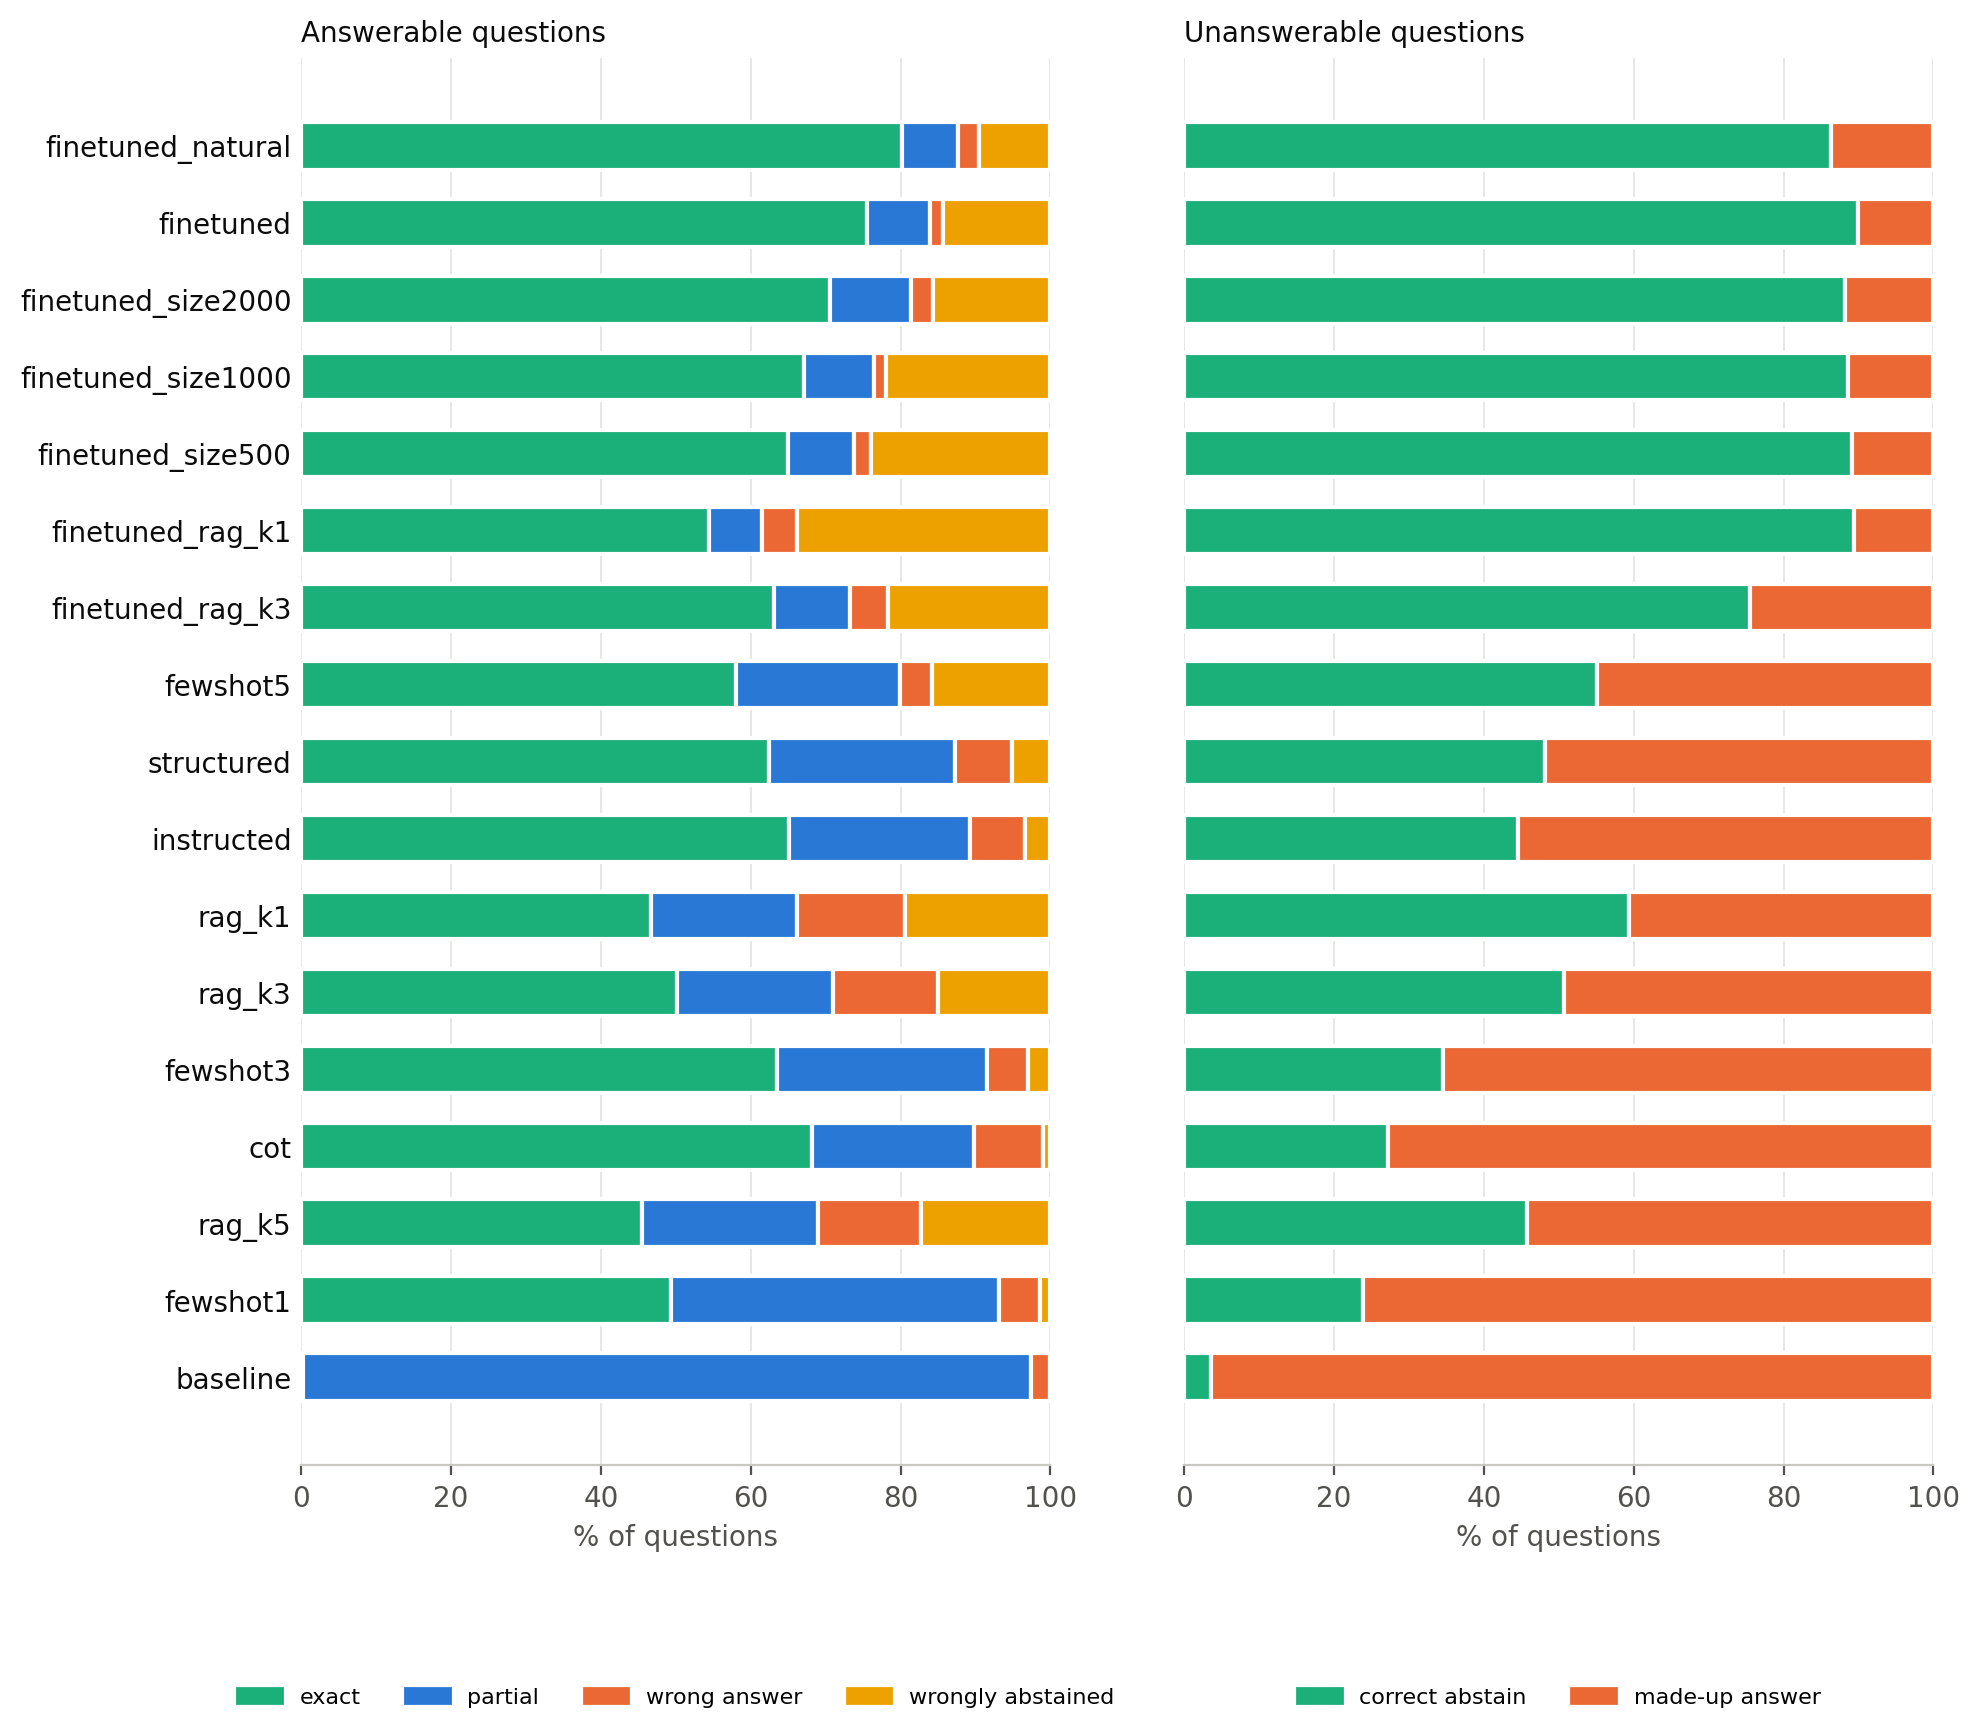

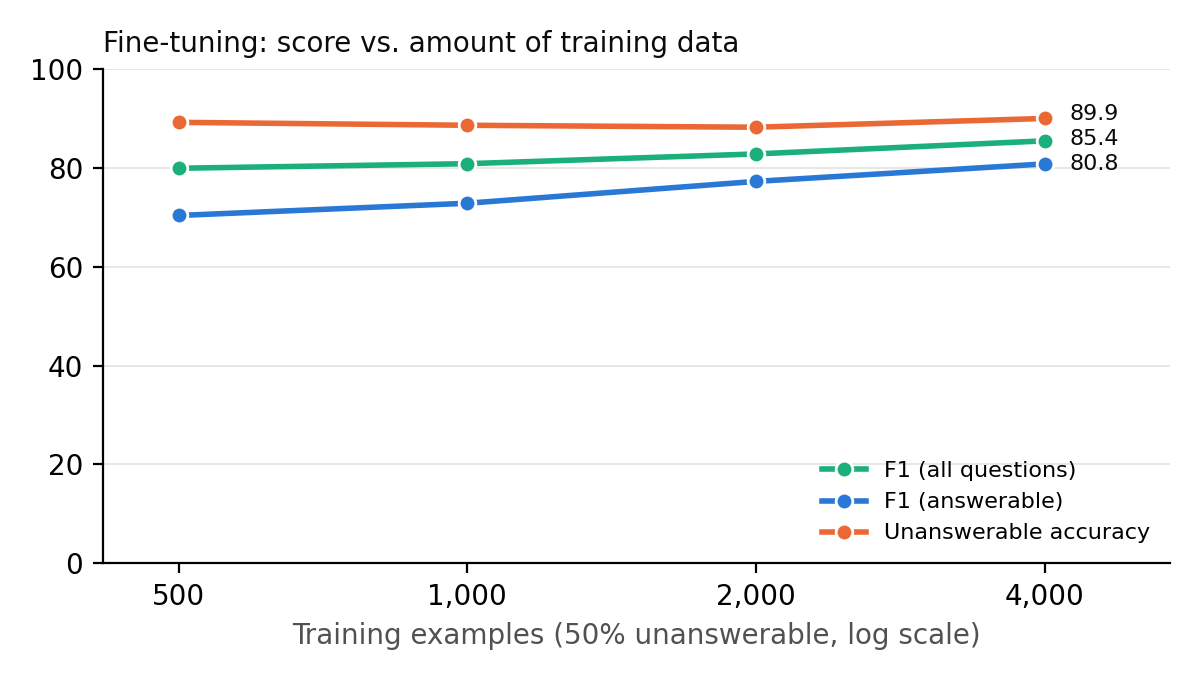

In [12]:
from IPython.display import Image, display
for c in ["f1_confidence_intervals", "error_types", "training_size_curve"]:
    display(Image(f"results/analysis/{c}.png"))

In [13]:
!git config user.name "Ekemini John"
!git config user.email "johnkemi25@gmail.com"
!git add results/analysis/
!git commit -m "Phase 7: confidence intervals, paired tests, error and question-type analysis"
!git push origin analysis

[analysis db869c5] Phase 7: confidence intervals, paired tests, error and question-type analysis
 7 files changed, 215 insertions(+)
 create mode 100644 results/analysis/by_question_type.csv
 create mode 100644 results/analysis/confidence_intervals.csv
 create mode 100644 results/analysis/error_types.csv
 create mode 100644 results/analysis/error_types.png
 create mode 100644 results/analysis/f1_confidence_intervals.png
 create mode 100644 results/analysis/paired_tests.csv
 create mode 100644 results/analysis/training_size_curve.png
Enumerating objects: 13, done.
Counting objects: 100% (13/13), done.
Delta compression using up to 2 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (11/11), 258.94 KiB | 12.33 MiB/s, done.
Total 11 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/Kairos-025/llm-qa-project.git
   8f44696..db869c5  analysis -> analysis
